Phishing Website Detection Analysis

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

df = pd.read_csv(r"C:\Users\Lana\Downloads\dataset1.csv")
df.columns = df.columns.str.strip()
df = df.drop(columns=['index'])


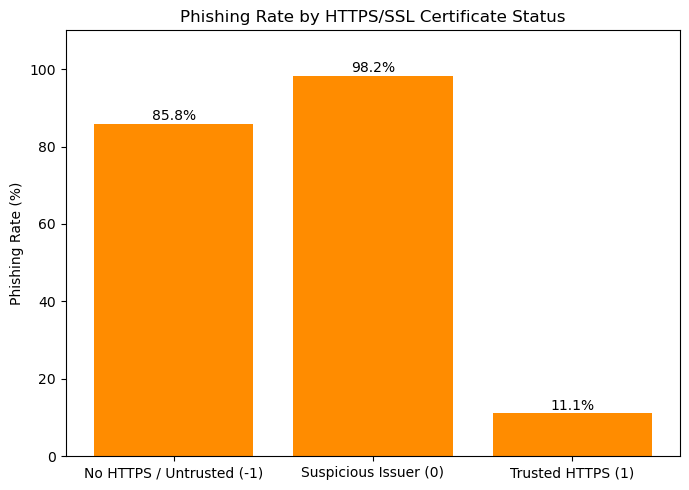

In [6]:
#Graph 1 HTTPS/SSL certificate status

ssl_table = pd.crosstab(df['SSLfinal_State'], df['Result'])
ssl_table['phishing_rate'] = ssl_table[-1] / (ssl_table[-1] + ssl_table[1]) * 100
labels = ['No HTTPS / Untrusted (-1)', 'Suspicious Issuer (0)', 'Trusted HTTPS (1)']

plt.figure(figsize=(7,5))
plt.bar(labels, ssl_table['phishing_rate'], color='darkorange')
plt.ylabel('Phishing Rate (%)')
plt.title('Phishing Rate by HTTPS/SSL Certificate Status')
for i, v in enumerate(ssl_table['phishing_rate']):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center')
plt.ylim(0,110)
plt.tight_layout()
plt.show()

Caption: Percent of URLs that are phishing, broken down by HTTPS/SSL certificate status

Graph 1 Interpretation:

The graph shows a huge gap. URLs with no HTTPS or an untrusted certificate are 
phishing 85.8% of the time, and ones with a suspicious certificate issuer are phishing
98.2% of the time. But URLs with a properly trusted HTTPS certificate are phishing only
11.1% of the time. Out of the three indicators I'm looking at, this is the one that
actually separates phishing from legitimate sites well, which makes sense since
getting a trusted certificate takes more legitimacy and effor than a phishing
operation usually has.


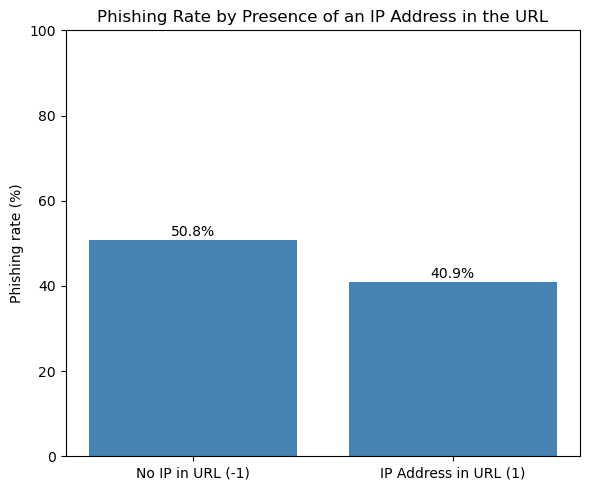

In [7]:
# Graph 2 IP address in the URL

ip_table = pd.crosstab(df['having_IPhaving_IP_Address'], df['Result'])
ip_table['phishing_rate'] = ip_table[-1] / (ip_table[-1] + ip_table[1]) * 100
labels = ['No IP in URL (-1)', 'IP Address in URL (1)']

plt.figure(figsize=(6,5))
plt.bar(labels, ip_table['phishing_rate'], color='steelblue')
plt.ylabel('Phishing rate (%)')
plt.title('Phishing Rate by Presence of an IP Address in the URL')
for i, v in enumerate(ip_table['phishing_rate']):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center')
plt.ylim(0,100)
plt.tight_layout()
plt.show()

Caption: Percent of URLs that are phishing, split by whether the URL used raw IP address instead of domain name.

Graph 2 Interpretation:

URLs without an IP address are phishing 50.8% of the time, and URLs that do have one are phishing 40.9% of the time. That's basically a coin flip either way, and the direction is actually backwards from what I expected. URLs with IP addresses are slightly less likely to be phishing in this dataset, not more. This tells me having an IP address in the URL isn't a reliable indicator on its own, even though it's often listed as a classic phishing red flag. 

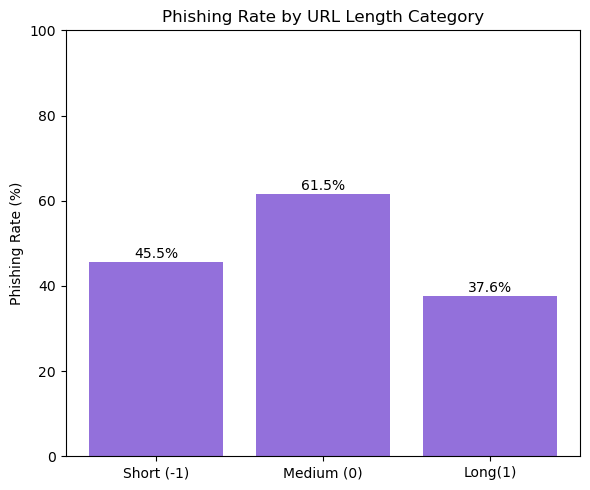

In [8]:
# Graph 3 URL length

len_table = pd.crosstab(df['URLURL_Length'], df['Result'])
len_table['phishing_rate'] = len_table[-1] / (len_table[-1] + len_table[1]) * 100
labels = ['Short (-1)', 'Medium (0)', 'Long(1)']

plt.figure(figsize=(6,5))
plt.bar(labels, len_table['phishing_rate'], color='mediumpurple')
plt.ylabel('Phishing Rate (%)')
plt.title('Phishing Rate by URL Length Category')
for i, v in enumerate(len_table['phishing_rate']):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center')
plt.ylim(0,100)
plt.tight_layout()
plt.show()

Caption: Percent of URLs that are phishing, split by whether the URL used raw IP address instead of a domain name.

Graph 3 Interpretation:

Phishing rate is 45.5% for short URLs, 61.5% for medium length URLs, and 37.6% for long URLs. There's no clean trend here. It doesn't go up or down steadily as the URL gets longer, it just bounces around. The medium category is also the smallest group by far, so that 61.5% number is less reliable than the other two. Overall, URL length doesn't look like a strong or consistent predictor of phishing on its own. 

In [11]:
# Statistical Analysis: logistical regression using the three indicators
# from my research question, to see how well they predict phishing  together
# and which one matters most

y = (df['Result'] == -1).astype(int)
X = df[['URLURL_Length', 'having_IPhaving_IP_Address', 'SSLfinal_State']]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

pred = model.predict(X_test)
print('Accuracy:', accuracy_score(y_test, pred))

print('Coefficients:')
for name, coef in zip(X.columns, model.coef_[0]):
    print(f' {name}: {coef:.3f}')

Accuracy: 0.8833107191316146
Coefficients:
 URLURL_Length: -0.146
 having_IPhaving_IP_Address: -0.175
 SSLfinal_State: -2.090


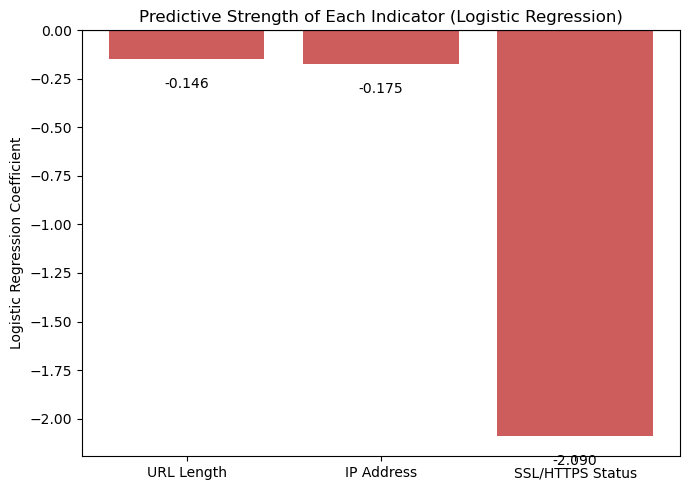

In [15]:
# visualize the logistic regression coefficients to show which indicator mattered most
coef_names = ['URL Length', 'IP Address', 'SSL/HTTPS Status']
coef_values = model.coef_[0]

plt.figure(figsize=(7,5))
colors = ['indianred' if v < 0 else 'seagreen' for v in coef_values]
plt.bar(coef_names, coef_values, color=colors)
plt.ylabel('Logistic Regression Coefficient')
plt.title('Predictive Strength of Each Indicator (Logistic Regression)')
plt.axhline(0, color='black', linewidth=0.8)
for i, v in enumerate(coef_values):
    offset = -0.15 if v < 0 else 0.05
    plt.text(i, v + offset, f'{v:.3f}', ha='center')
plt.tight_layout()
plt.show()

Caption: Logistic regression coefficients for URL length, IP address presence, and SSL/HTTPS status in predicting phishing. Larger magnitude (further from zero) means a stronger predictor. Negative values mean higher category values push toward "legitimate."

Interpretation paragraph: This graph puts all three indicators side by side on the same scale, and the difference is stark. The SSL/HTTPS status bar is roughly ten times larger than the other two, visually confirming what the correlation and phishing rate graphs already showed which is that SSL status is doing almost all of the predictive work, while URL length and IP address contribute only a small amount on their own. 

Summary Paragraph

These three graphs answer the question pretty directly. Traditional URL indicators are not all equally useful for spotting phishing. HTTPS/SSL certificate status (Graph 1) is a strong predictor, with phishing rate swinging from 11% for trusted HTTPS sites up to 86-98% for sites without one. Having an IP address in the URL (Graph 2) turned out to be a weak and even slightly backwards indicator, with phishing rates of 51% and 41% for the two groups, barely different from chance. URL length (Graph 3) was similarly weak and inconsistent, with phishing rates of 46%, 62%, and 38% across the three length categories and no clear pattern connecting length to phishing. Visually, this came through clearly too. The HTTPS graph has one bar that's dramatically different from the other two, while the IP address and URL length graphs look close to flat, which is itself a visual signal that those two indicators don't separate phishing from legitamate sites well. So while all three indicators are commonly mentioned as phishing warning signs, only HTTPS/SSL status actually holds up as a strong one in this dataset. 

To quantify how well these three indicators predict phishing beyond simple correlation, a logistic regression model was trained using URL length, IP address presence, and SSL status as predictors. The model correctly classified 88.3% of test-set websites using only these three features. The SSL status coefficient (-2.090) was more than ten times larger in magnitude than the URL length coefficient (-0.146) and the IP address coefficent (-0.175), confirming that SSL/HTTPS status is by far the strongest of the three predictors, consistent with the correlation analysis and visualizations.